# Chapter 9 – Neural Networks
**Kelompok:** Maizan Insani Akbar (242321011) · Muhammad Dicky Imansyah (242321030)

> Penjelasan tiap section ada di file `PENJELASAN.md`.

## 0. Instalasi Dependency

Jalankan sel di bawah **paling pertama** jika muncul error `No module named ...` (misal saat dijalankan di laptop/Jupyter lokal, bukan Colab). `%pip` memasang ke kernel yang sedang dipakai. Cukup sekali; setelah itu boleh di-skip.

In [1]:
# Pasang semua library yang dibutuhkan notebook ini (lokal & Colab).
%pip install -q numpy pandas matplotlib seaborn scikit-learn tensorflow keras ipywidgets
print('Selesai. Restart kernel bila baru pertama menginstal, lalu jalankan sel berikutnya.')

Note: you may need to restart the kernel to use updated packages.
Selesai. Restart kernel bila baru pertama menginstal, lalu jalankan sel berikutnya.


## 1. Setup

In [2]:
# Langkah 1: Import library utama (NumPy, Pandas, Matplotlib, Seaborn)
# Langkah 2: Import TensorFlow / Keras beserta layer yang dibutuhkan
# Langkah 3: Set random seed agar hasil reproducible
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras.models import Sequential, load_model
from keras.layers import Dense, Dropout

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
np.random.seed(42)
tf.random.set_seed(42)
tf.get_logger().setLevel('ERROR')  # diamkan WARNING retracing (tidak berbahaya)

TensorFlow: 2.20.0 | Keras: 3.13.2


## 2. Sequential API & Functional API

In [3]:
# Sequential API — susun layer satu per satu secara berurutan
# Langkah 1: Definisi input shape
# Langkah 2: Tambah hidden layer (ReLU) dan output layer
# Langkah 3: Tampilkan ringkasan arsitektur
contoh = Sequential([
    keras.Input(shape=(2,)),
    Dense(3, activation='relu'),
    Dense(1)
])
contoh.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Functional API — cocok untuk arsitektur bercabang / multi-input-output
# Langkah 1: Definisi tensor input eksplisit
# Langkah 2: Sambungkan layer secara manual (seperti rantai fungsi)
# Langkah 3: Bungkus jadi Model lalu tampilkan summary
inputs  = keras.Input(shape=(2,))
hidden  = Dense(128, activation='relu')(inputs)
outputs = Dense(1, activation='sigmoid')(hidden)
model_fn = keras.Model(inputs=inputs, outputs=outputs)
model_fn.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Regresi — Prediksi Tarif Taksi

In [5]:
# Langkah 1: Download dataset NYC Taxi Fares dari GitHub (~55 rb baris)
# Langkah 2: Filter hanya perjalanan 1 penumpang
# Langkah 3: Ekstrak fitur waktu (hari & jam) dari kolom datetime
# Langkah 4: Hitung jarak tempuh dari koordinat GPS (formula Euclidean)
# Langkah 5: Hapus outlier — filter jarak 1–10 mil & tarif $0–50
import urllib.request
url = "https://raw.githubusercontent.com/jeffprosise/Machine-Learning/master/Data/taxi-fares.csv"
urllib.request.urlretrieve(url, "taxi-fares.csv")

df = pd.read_csv("taxi-fares.csv", parse_dates=['pickup_datetime'])

# Preprocessing mengikuti buku (versi vektorisasi, lebih cepat dari iterrows)
df = df[df['passenger_count'] == 1].copy()
df = df.drop(['key', 'passenger_count'], axis=1)
df['day_of_week'] = df['pickup_datetime'].dt.weekday.astype(float)   # 0=Senin
df['pickup_time'] = df['pickup_datetime'].dt.hour.astype(float)      # 0-23
dx = (df['dropoff_longitude'] - df['pickup_longitude']) * 54.6
dy = (df['dropoff_latitude']  - df['pickup_latitude'])  * 69.0
df['distance'] = np.sqrt(dx**2 + dy**2)
df = df.drop(['pickup_datetime','pickup_longitude','pickup_latitude',
              'dropoff_longitude','dropoff_latitude'], axis=1)
df = df[(df['distance'] > 1.0) & (df['distance'] < 10.0)]
df = df[(df['fare_amount'] > 0.0) & (df['fare_amount'] < 50.0)]
print("Jumlah baris siap latih:", len(df))
df.head()

Jumlah baris siap latih: 23298


,fare_amount,day_of_week,pickup_time,distance
2,6.1,0.0,15.0,1.038136
4,10.5,5.0,10.0,2.924341
5,15.3,4.0,20.0,4.862893
8,7.7,5.0,1.0,2.603493
9,8.9,3.0,16.0,1.365739


In [6]:
# Langkah 1: Pisahkan fitur (x) dan target tarif (y)
# Langkah 2: Bangun model regresi — 2 hidden layer 512 neuron, output 1 neuron
# Langkah 3: Compile dengan optimizer Adam dan loss MAE (Mean Absolute Error)
x = df.drop('fare_amount', axis=1)
y = df['fare_amount']
model_taxi = Sequential([
    keras.Input(shape=(3,)),
    Dense(512, activation='relu'),
    Dense(512, activation='relu'),
    Dense(1)
])
model_taxi.compile(optimizer='adam', loss='mae', metrics=['mae'])
model_taxi.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 265,217 (1.01 MB)

 Trainable params: 265,217 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Langkah 1: Latih model 50 epoch, 20% data untuk validasi
# Langkah 2: Tampilkan MAE validasi akhir
hist = model_taxi.fit(x, y, validation_split=0.2,
                      epochs=50, batch_size=100, verbose=0)
print("val_mae akhir:", round(hist.history['val_mae'][-1], 3))

val_mae akhir: 2.264


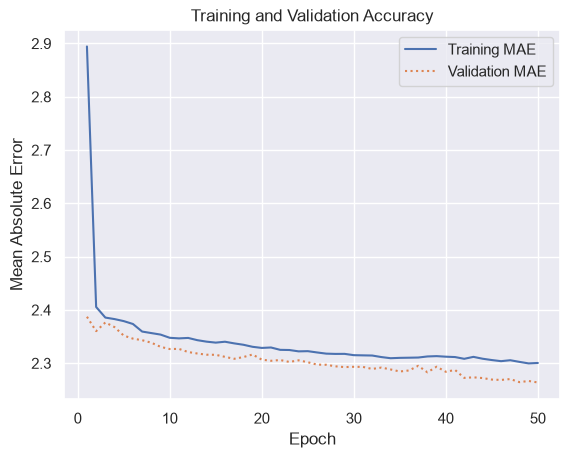

In [8]:
# Langkah 1: Ambil riwayat MAE training dan validasi
# Langkah 2: Plot kurva learning untuk cek apakah model konvergen / overfit
sns.set()
err, val_err = hist.history['mae'], hist.history['val_mae']
ep = range(1, len(err) + 1)
plt.plot(ep, err, '-', label='Training MAE')
plt.plot(ep, val_err, ':', label='Validation MAE')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Mean Absolute Error')
plt.legend(loc='upper right'); plt.show()

In [9]:
# Evaluasi akhir: hitung R² score — seberapa baik model menjelaskan variansi tarif
from sklearn.metrics import r2_score
r2 = r2_score(y, model_taxi.predict(x, verbose=0).flatten())
print("R^2:", round(r2, 3))

R^2: 0.744


In [10]:
# Contoh inferensi: prediksi tarif hari Jumat vs Sabtu, jam 17, jarak 2 mil
jumat = model_taxi.predict(np.array([[4, 17, 2.0]]), verbose=0)[0][0]
sabtu = model_taxi.predict(np.array([[5, 17, 2.0]]), verbose=0)[0][0]
print(f"Jumat 17:00, 2 mil: ${jumat:.2f}")
print(f"Sabtu 17:00, 2 mil: ${sabtu:.2f}")

Jumat 17:00, 2 mil: $10.32
Sabtu 17:00, 2 mil: $10.06


## 4. Klasifikasi Biner — Pima Indians Diabetes

Sampel: 768 | Diabetes: 268 (34.9%)


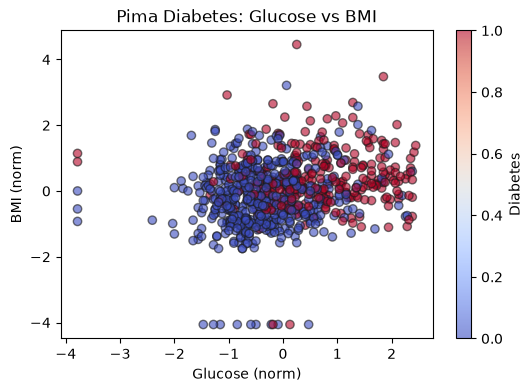

In [11]:
# Langkah 1: Download dataset Pima Indians Diabetes dari GitHub (mirror UCI)
# Langkah 2: Beri nama kolom secara manual (CSV tidak punya header)
# Langkah 3: Pisahkan fitur (x) dan label (y)
# Langkah 4: Normalisasi fitur dengan StandardScaler
# Langkah 5: Visualisasi sebaran Glucose vs BMI berdasarkan kelas
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

url_pima = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
cols = ['pregnancies','glucose','blood_pressure','skin_thickness',
        'insulin','bmi','diabetes_pedigree','age','outcome']
df_pima = pd.read_csv(url_pima, names=cols)
print("Sampel:", len(df_pima), "| Diabetes:", df_pima['outcome'].sum(),
      f"({100*df_pima['outcome'].mean():.1f}%)")

x_pima = df_pima.drop('outcome', axis=1).values.astype('float32')
y_pima = df_pima['outcome'].values.astype('float32')
scaler_pima = StandardScaler()
x_pima = scaler_pima.fit_transform(x_pima)

# Visualisasi 2 fitur paling informatif
sns.reset_orig()
plt.figure(figsize=(6,4))
plt.scatter(x_pima[:,1], x_pima[:,5], c=y_pima, cmap='coolwarm', edgecolor='k', alpha=0.6)
plt.xlabel('Glucose (norm)'); plt.ylabel('BMI (norm)')
plt.title('Pima Diabetes: Glucose vs BMI')
plt.colorbar(label='Diabetes'); plt.show()


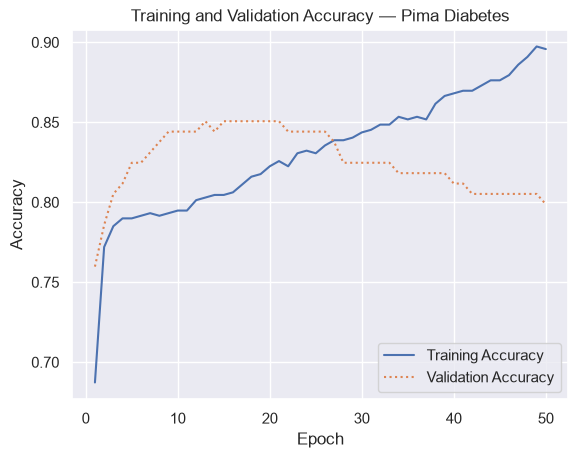

In [12]:
# Langkah 1: Bangun model biner — input 8 fitur, 2 hidden layer, output sigmoid
# Langkah 2: Split data 80/20 dengan stratify agar proporsi kelas seimbang
# Langkah 3: Latih 50 epoch lalu plot kurva akurasi training vs validasi
model_bin = Sequential([
    keras.Input(shape=(8,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_bin.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
x_tr_p, x_te_p, y_tr_p, y_te_p = train_test_split(
    x_pima, y_pima, test_size=0.2, stratify=y_pima, random_state=0)
hist = model_bin.fit(x_tr_p, y_tr_p, epochs=50, batch_size=16,
                     validation_data=(x_te_p, y_te_p), verbose=0)
sns.set()
acc, val = hist.history['accuracy'], hist.history['val_accuracy']
ep = range(1, len(acc)+1)
plt.plot(ep, acc, '-', label='Training Accuracy')
plt.plot(ep, val, ':', label='Validation Accuracy')
plt.title('Training and Validation Accuracy — Pima Diabetes')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(loc='lower right'); plt.show()


In [13]:
# Contoh inferensi: masukkan data satu pasien, prediksi probabilitas diabetes
# Input harus dinormalisasi dulu dengan scaler yang sama seperti saat training
sample_raw = np.array([[6, 148, 72, 35, 0, 33.6, 0.627, 50]], dtype='float32')
sample = scaler_pima.transform(sample_raw)
p = model_bin.predict(sample, verbose=0)
print("Probabilitas diabetes:", round(float(p[0][0]), 3), "| Kelas:", int((p > 0.5)[0][0]))


Probabilitas diabetes: 0.949 | Kelas: 1


## 5. Klasifikasi Biner — Deteksi Penipuan & Confusion Matrix

In [14]:
# Langkah 1: Download dataset Credit Card Fraud dari mirror GitHub (60 rb transaksi)
# Langkah 2: Cek distribusi kelas — sangat imbalanced (hanya 0.25% fraud)
# Langkah 3: Hapus kolom Time, pisahkan fitur dan label
# Langkah 4: Split 80/20 dengan stratify untuk menjaga proporsi fraud di tiap split
from sklearn.model_selection import train_test_split
import urllib.request
url = "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"
urllib.request.urlretrieve(url, "creditcard.csv")

df_fraud = pd.read_csv("creditcard.csv")
print("Sampel:", len(df_fraud), "| Penipuan:", int(df_fraud['Class'].sum()),
      f"({100*df_fraud['Class'].mean():.3f}%)")

x  = df_fraud.drop(['Time', 'Class'], axis=1)   # 29 fitur (V1..V28 + Amount)
yv = df_fraud['Class']
x_train, x_test, y_train, y_test = train_test_split(
    x, yv, test_size=0.2, stratify=yv, random_state=0)

Sampel: 284807 | Penipuan: 492 (0.173%)


In [15]:
# Langkah 1: Bangun model biner — input 29 fitur, 1 hidden layer, output sigmoid
# Langkah 2: Latih 10 epoch dengan validation_data (bukan validation_split)
# Langkah 3: Tampilkan akurasi validasi akhir
model_fraud = Sequential([
    keras.Input(shape=(29,)),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_fraud.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
hist = model_fraud.fit(x_train, y_train, validation_data=(x_test, y_test),
                       epochs=10, batch_size=100, verbose=0)
print("val_accuracy akhir:", round(hist.history['val_accuracy'][-1], 5))

val_accuracy akhir: 0.99939


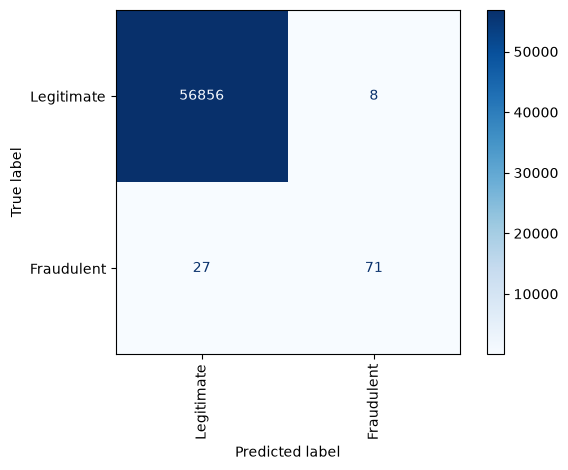

              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00     56864
       Fraud       0.90      0.72      0.80        98

    accuracy                           1.00     56962
   macro avg       0.95      0.86      0.90     56962
weighted avg       1.00      1.00      1.00     56962



In [16]:
# Langkah 1: Ambil prediksi kelas dari probabilitas (threshold 0.5)
# Langkah 2: Tampilkan confusion matrix — lihat berapa fraud yang terdeteksi
# Langkah 3: Tampilkan Precision, Recall, F1 — lebih relevan dari Accuracy untuk data imbalanced
from sklearn.metrics import ConfusionMatrixDisplay as cmd, classification_report
sns.reset_orig()
y_pred_fraud = (model_fraud.predict(x_test, verbose=0) > 0.5).astype(int)
cmd.from_predictions(y_test, y_pred_fraud, display_labels=['Legitimate','Fraudulent'],
                     cmap='Blues', xticks_rotation='vertical')
plt.tight_layout(); plt.show()
# Accuracy saja menyesatkan pada data imbalanced — pakai Recall & F1
print(classification_report(y_test, y_pred_fraud, target_names=['Legit','Fraud']))


## 6. Klasifikasi Multikelas — MNIST 4 Digit

Train: (24754, 784) | Test: (4157, 784)
Distribusi kelas train: {0: 5923, 1: 6742, 2: 5958, 3: 6131}


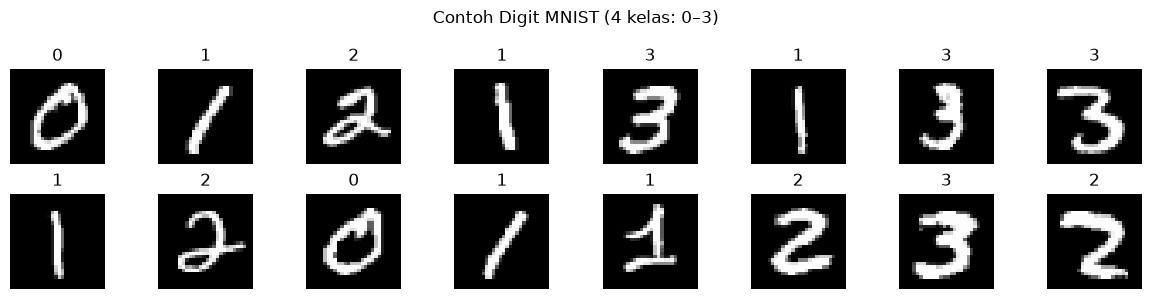

In [17]:
# Langkah 1: Load MNIST langsung dari Keras (70 rb gambar 28x28 piksel)
# Langkah 2: Filter hanya digit 0, 1, 2, 3 untuk klasifikasi 4 kelas
# Langkah 3: Flatten gambar 28x28 → vektor 784 fitur, normalisasi ke [0,1]
# Langkah 4: Visualisasi contoh gambar dari tiap kelas
(x_mn_tr, y_mn_tr), (x_mn_te, y_mn_te) = keras.datasets.mnist.load_data()

mask_tr = y_mn_tr < 4
mask_te = y_mn_te < 4
x_mn_tr = x_mn_tr[mask_tr].reshape(-1, 784).astype('float32') / 255.0
y_mn_tr = y_mn_tr[mask_tr]
x_mn_te = x_mn_te[mask_te].reshape(-1, 784).astype('float32') / 255.0
y_mn_te = y_mn_te[mask_te]

print("Train:", x_mn_tr.shape, "| Test:", x_mn_te.shape)
print("Distribusi kelas train:", {int(k):int(v) for k,v in zip(*np.unique(y_mn_tr, return_counts=True))})

sns.reset_orig()
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_mn_tr[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_mn_tr[i])); ax.axis('off')
plt.suptitle('Contoh Digit MNIST (4 kelas: 0–3)'); plt.tight_layout(); plt.show()


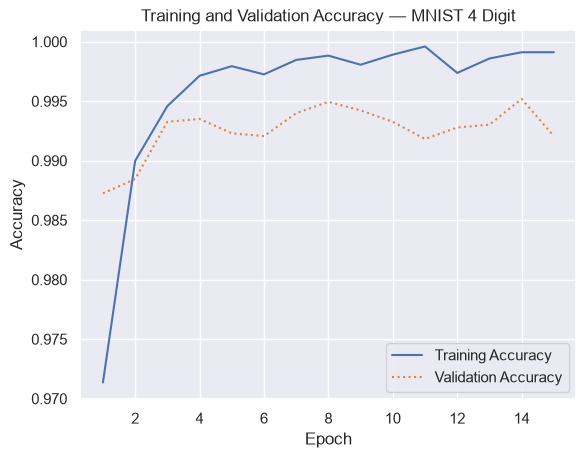

In [18]:
# Langkah 1: Bangun model multikelas — input 784, 2 hidden layer, output softmax 4 kelas
# Langkah 2: Compile dengan sparse_categorical_crossentropy (label integer, bukan one-hot)
# Langkah 3: Latih 15 epoch lalu plot kurva akurasi
model_multi = Sequential([
    keras.Input(shape=(784,)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(4, activation='softmax')
])
model_multi.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist = model_multi.fit(x_mn_tr, y_mn_tr, epochs=15, batch_size=64,
                       validation_data=(x_mn_te, y_mn_te), verbose=0)
sns.set()
acc, val = hist.history['accuracy'], hist.history['val_accuracy']
ep = range(1, len(acc)+1)
plt.plot(ep, acc, '-', label='Training Accuracy')
plt.plot(ep, val, ':', label='Validation Accuracy')
plt.title('Training and Validation Accuracy — MNIST 4 Digit')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(loc='lower right'); plt.show()


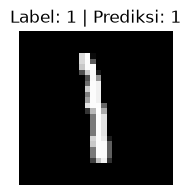

Probabilitas: [0. 1. 0. 0.] | Kelas: 1


In [19]:
# Contoh inferensi: prediksi satu gambar, tampilkan gambarnya dan probabilitas tiap kelas
idx = 10
probs = model_multi.predict(x_mn_te[idx:idx+1], verbose=0)
pred = int(np.argmax(probs))
sns.reset_orig()
plt.figure(figsize=(2,2))
plt.imshow(x_mn_te[idx].reshape(28,28), cmap='gray'); plt.axis('off')
plt.title(f"Label: {y_mn_te[idx]} | Prediksi: {pred}"); plt.show()
print("Probabilitas:", np.round(probs[0], 4), "| Kelas:", pred)


## 7. Pengenalan Wajah (LFW)

In [20]:
# Langkah 1: Download dataset LFW via sklearn (min. 100 foto per orang)
# Langkah 2: Crop gambar ke region wajah saja [35:97, 39:86]
# Langkah 3: Flatten gambar 62x47 → vektor 2914 fitur
# Langkah 4: Tampilkan jumlah gambar dan daftar 5 tokoh yang dikenali
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=100, slice_=None)
faces.images = faces.images[:, 35:97, 39:86]
faces.data = faces.images.reshape(faces.images.shape[0],
                                  faces.images.shape[1] * faces.images.shape[2])
image_height = faces.images.shape[1]
image_width  = faces.images.shape[2]
class_count  = len(faces.target_names)
print("Gambar:", faces.images.shape[0], "| Ukuran:", image_width, "x", image_height)
print("Orang:", class_count, "->", list(faces.target_names))

Gambar: 1140 | Ukuran: 47 x 62
Orang: 5 -> [np.str_('Colin Powell'), np.str_('Donald Rumsfeld'), np.str_('George W Bush'), np.str_('Gerhard Schroeder'), np.str_('Tony Blair')]


In [21]:
# Langkah 1: Batasi maksimal 100 foto per orang agar tiap kelas seimbang
# Langkah 2: Split data 80/20 dengan stratify
mask = np.zeros(faces.target.shape, dtype=bool)
for target in np.unique(faces.target):
    mask[np.where(faces.target == target)[0][:100]] = 1
x_faces = faces.data[mask]
y_faces = faces.target[mask]
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x_faces, y_faces, train_size=0.8, stratify=y_faces, random_state=0)
print("Data:", x_faces.shape)

Data: (500, 2914)


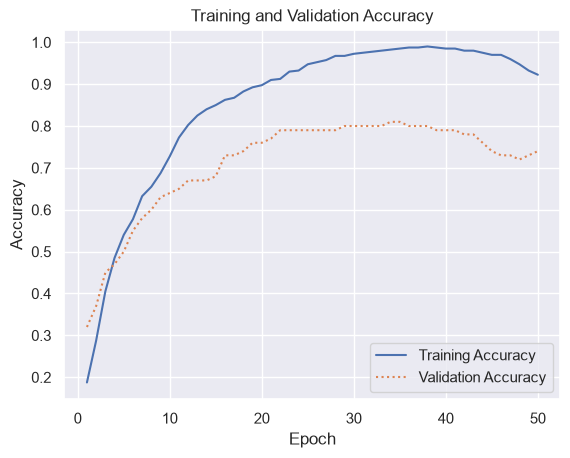

In [22]:
# Langkah 1: Bangun model — input 2914 fitur, hidden 512 neuron, output softmax 5 kelas
# Langkah 2: Latih 50 epoch lalu plot kurva akurasi training vs validasi
model_face = Sequential([
    keras.Input(shape=(image_width * image_height,)),
    Dense(512, activation='relu'),
    Dense(class_count, activation='softmax')
])
model_face.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist = model_face.fit(x_train, y_train, validation_data=(x_test, y_test),
                      epochs=50, batch_size=20, verbose=0)
sns.set()
acc, val_acc = hist.history['accuracy'], hist.history['val_accuracy']
ep = range(1, len(acc)+1)
plt.plot(ep, acc, '-', label='Training Accuracy')
plt.plot(ep, val_acc, ':', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(loc='lower right'); plt.show()

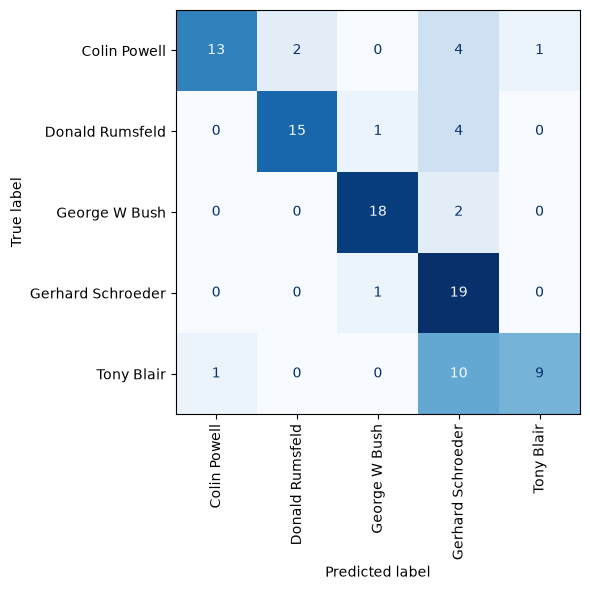

In [23]:
# Langkah 1: Prediksi kelas dari test set
# Langkah 2: Tampilkan confusion matrix berlabel nama tokoh
from sklearn.metrics import ConfusionMatrixDisplay as cmd
sns.reset_orig()
y_pred = model_face.predict(x_test, verbose=0).argmax(axis=1)
fig, ax = plt.subplots(figsize=(6, 6)); ax.grid(False)
cmd.from_predictions(y_test, y_pred, display_labels=faces.target_names,
                     colorbar=False, cmap='Blues', xticks_rotation='vertical', ax=ax)
plt.tight_layout(); plt.show()

## 8. Dropout

In [24]:
# Langkah 1: Arsitektur sama seperti model wajah, tambahkan Dropout(0.2) setelah hidden layer
# Langkah 2: Dropout menonaktifkan 20% neuron secara acak tiap batch — mencegah overfitting
# Langkah 3: Bandingkan val_accuracy dengan model tanpa dropout
model_drop = Sequential([
    keras.Input(shape=(image_width * image_height,)),
    Dense(512, activation='relu'),
    Dropout(0.2),
    Dense(class_count, activation='softmax')
])
model_drop.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist = model_drop.fit(x_train, y_train, validation_data=(x_test, y_test),
                      epochs=50, batch_size=20, verbose=0)
print("val_accuracy (dropout):", round(hist.history['val_accuracy'][-1], 4))

val_accuracy (dropout): 0.74


## 9. Menyimpan & Memuat Model

In [25]:
# Langkah 1: Simpan model ke file .keras (format Keras native)
# Langkah 2: Muat kembali model dari file
# Langkah 3: Verifikasi — prediksi model asli vs model dimuat harus identik
model_face.save('model_wajah.keras')
model_dimuat = load_model('model_wajah.keras')
a = model_face.predict(x_test[:5], verbose=0)
b = model_dimuat.predict(x_test[:5], verbose=0)
print("Prediksi identik?", np.allclose(a, b))

Prediksi identik? True


## 10. Keras Callbacks

In [26]:
# Langkah 1: Buat custom callback — hentikan training otomatis jika val_accuracy tercapai
# Langkah 2: Siapkan subset MNIST sebagai data latih untuk demo callback
# Langkah 3: Latih model dengan StopCallback — training berhenti sendiri saat target tercapai
from keras.callbacks import Callback, EarlyStopping, ModelCheckpoint

class StopCallback(Callback):
    def __init__(self, threshold):
        self.threshold = threshold
    def on_epoch_end(self, epoch, logs=None):
        if logs.get('val_accuracy', 0) >= self.threshold:
            print(f"\nval_accuracy >= {self.threshold} di epoch {epoch+1}, berhenti.")
            self.model.stop_training = True

# Gunakan subset MNIST dari Section 6
x_cb, y_cb = x_mn_tr[:5000], y_mn_tr[:5000]
x_cb_val, y_cb_val = x_mn_te[:1000], y_mn_te[:1000]

model_cb = Sequential([keras.Input(shape=(784,)),
                       Dense(128, activation='relu'),
                       Dense(4, activation='softmax')])
model_cb.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cb.fit(x_cb, y_cb, validation_data=(x_cb_val, y_cb_val),
             epochs=50, batch_size=32,
             callbacks=[StopCallback(0.99)], verbose=0)


In [27]:
# Langkah 1: EarlyStopping — berhenti jika val_accuracy tidak naik selama 5 epoch
# Langkah 2: ModelCheckpoint — simpan otomatis bobot terbaik ke best_model.keras
# Langkah 3: Dua callback dijalankan bersamaan dalam satu list
early = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
ckpt  = ModelCheckpoint(filepath='best_model.keras',
                        monitor='val_accuracy', save_best_only=True)
model_cb2 = Sequential([keras.Input(shape=(784,)),
                        Dense(128, activation='relu'),
                        Dense(4, activation='softmax')])
model_cb2.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cb2.fit(x_cb, y_cb, validation_data=(x_cb_val, y_cb_val),
              epochs=50, batch_size=32,
              callbacks=[early, ckpt], verbose=0)
print("Model terbaik -> best_model.keras")


Model terbaik -> best_model.keras


In [28]:
# Langkah 1: TensorBoard — catat metrik dan histogram bobot ke folder 'logs'
# Langkah 2: Jalankan training dengan callback TensorBoard aktif
# Langkah 3: Di Colab, buka dengan: %load_ext tensorboard && %tensorboard --logdir logs
from keras.callbacks import TensorBoard
tb = TensorBoard(log_dir='logs', histogram_freq=1)
model_cb2.fit(x_cb, y_cb, validation_data=(x_cb_val, y_cb_val),
              epochs=20, batch_size=32, callbacks=[tb], verbose=0)
print("Log tersimpan di folder 'logs'.")
# Untuk melihatnya di Colab:
# %load_ext tensorboard
# %tensorboard --logdir logs


Log tersimpan di folder 'logs'.


## 11. GUI Interaktif — Dashboard Prediksi

Antarmuka satu-pintu untuk mencoba seluruh model: cukup pilih tab, atur input lewat slider, lalu klik tombol prediksi.


In [29]:
# ============================================================
# Langkah 1: Import ipywidgets (Google Colab sudah menyediakannya)
# Langkah 2: Bangun dashboard dengan tab per model
# Langkah 3: Jalankan sel ini SETELAH semua model di atas dilatih
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# ---- Tema warna konsisten ----
PRIMARY, OK, WARN, BG = "#2563eb", "#16a34a", "#dc2626", "#f1f5f9"
SLIDER_STYLE = {"description_width": "150px"}
SLIDER_LAYOUT = widgets.Layout(width="96%")


def kartu(isi, warna=PRIMARY):
    """Bungkus hasil prediksi dalam kartu rapi."""
    return HTML(
        f"<div style='padding:18px;border-radius:12px;background:{BG};"
        f"border-left:6px solid {warna};font-family:system-ui;margin-top:8px'>{isi}</div>"
    )


def tombol(teks, ikon):
    return widgets.Button(
        description=teks, button_style="primary", icon=ikon,
        layout=widgets.Layout(width="220px", height="40px"),
    )


tabs, judul = [], []

# ====================== TAB 1: TAKSI (Regresi) ======================
if "model_taxi" in globals():
    hari_map = {"Senin": 0, "Selasa": 1, "Rabu": 2, "Kamis": 3,
                "Jumat": 4, "Sabtu": 5, "Minggu": 6}
    t_hari = widgets.Dropdown(options=list(hari_map), value="Jumat",
                              description="Hari:", style=SLIDER_STYLE)
    t_jam = widgets.IntSlider(value=17, min=0, max=23, description="Jam (0-23):",
                              style=SLIDER_STYLE, layout=SLIDER_LAYOUT)
    t_jarak = widgets.FloatSlider(value=2.0, min=1.0, max=10.0, step=0.1,
                                  description="Jarak (mil):",
                                  style=SLIDER_STYLE, layout=SLIDER_LAYOUT)
    t_btn = tombol("Prediksi Tarif", "taxi")
    t_out = widgets.Output()

    def t_predict(_):
        with t_out:
            clear_output()
            X = np.array([[hari_map[t_hari.value], t_jam.value, t_jarak.value]],
                         dtype="float32")
            fare = float(model_taxi.predict(X, verbose=0)[0][0])
            display(kartu(
                f"<h1 style='margin:0;color:{PRIMARY}'>${fare:.2f}</h1>"
                f"<p style='margin:6px 0 0;color:#475569'>{t_hari.value}, "
                f"jam {t_jam.value}:00, jarak {t_jarak.value} mil</p>"))

    t_btn.on_click(t_predict)
    tabs.append(widgets.VBox([
        widgets.HTML("<p style='color:#475569'>Prediksi <b>tarif taksi NYC</b> "
                     "dari hari, jam, dan jarak tempuh.</p>"),
        t_hari, t_jam, t_jarak, t_btn, t_out]))
    judul.append("Taksi")

# ====================== TAB 2: DIABETES (Klasifikasi Biner) ======================
if "model_bin" in globals() and "scaler_pima" in globals():
    fields = [
        ("Kehamilan", 0, 17, 1, 3),
        ("Glukosa", 0, 200, 1, 120),
        ("Tekanan Darah", 0, 122, 1, 70),
        ("Tebal Kulit", 0, 99, 1, 20),
        ("Insulin", 0, 846, 1, 79),
        ("BMI", 0.0, 67.0, 0.1, 32.0),
        ("Riwayat Keluarga", 0.0, 2.5, 0.01, 0.47),
        ("Usia", 21, 81, 1, 33),
    ]
    d_widgets = []
    for label, lo, hi, step, val in fields:
        Slider = widgets.FloatSlider if isinstance(step, float) else widgets.IntSlider
        d_widgets.append(Slider(value=val, min=lo, max=hi, step=step,
                                description=label + ":",
                                style=SLIDER_STYLE, layout=SLIDER_LAYOUT))
    d_btn = tombol("Prediksi Risiko", "heartbeat")
    d_out = widgets.Output()

    def d_predict(_):
        with d_out:
            clear_output()
            vals = np.array([[w.value for w in d_widgets]], dtype="float32")
            p = float(model_bin.predict(scaler_pima.transform(vals), verbose=0)[0][0])
            if p > 0.5:
                display(kartu(
                    f"<h2 style='margin:0;color:{WARN}'>⚠ Berisiko Diabetes</h2>"
                    f"<p style='margin:6px 0 0'>Probabilitas: <b>{p*100:.1f}%</b></p>",
                    WARN))
            else:
                display(kartu(
                    f"<h2 style='margin:0;color:{OK}'>✓ Risiko Rendah</h2>"
                    f"<p style='margin:6px 0 0'>Probabilitas: <b>{p*100:.1f}%</b></p>",
                    OK))

    d_btn.on_click(d_predict)
    tabs.append(widgets.VBox([
        widgets.HTML("<p style='color:#475569'>Prediksi <b>risiko diabetes</b> "
                     "dari 8 indikator klinis pasien.</p>"),
        *d_widgets, d_btn, d_out]))
    judul.append("Diabetes")

# ====================== TAB 3: MNIST (Klasifikasi Multikelas) ======================
if "model_multi" in globals() and "x_mn_te" in globals():
    m_btn = tombol("Ambil Digit Acak", "random")
    m_out = widgets.Output()

    def m_predict(_):
        with m_out:
            clear_output()
            i = np.random.randint(len(x_mn_te))
            probs = model_multi.predict(x_mn_te[i:i + 1], verbose=0)[0]
            pred = int(np.argmax(probs))
            benar = pred == int(y_mn_te[i])
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
            ax1.imshow(x_mn_te[i].reshape(28, 28), cmap="gray")
            ax1.axis("off")
            ax1.set_title(f"Asli: {y_mn_te[i]} | Prediksi: {pred}",
                          color="green" if benar else "red")
            ax2.bar(range(4), probs, color=PRIMARY)
            ax2.set_xticks(range(4))
            ax2.set_ylim(0, 1)
            ax2.set_title("Probabilitas tiap kelas")
            plt.tight_layout()
            plt.show()

    m_btn.on_click(m_predict)
    tabs.append(widgets.VBox([
        widgets.HTML("<p style='color:#475569'>Ambil <b>digit tulisan tangan</b> "
                     "acak dari data uji, lalu prediksi (0-3).</p>"),
        m_btn, m_out]))
    judul.append("MNIST")

# ====================== TAB 4: WAJAH (Pengenalan Wajah) ======================
if all(v in globals() for v in ("model_face", "x_test", "y_test", "faces")):
    w_btn = tombol("Ambil Wajah Acak", "user")
    w_out = widgets.Output()

    def w_predict(_):
        with w_out:
            clear_output()
            i = np.random.randint(len(x_test))
            pred = int(model_face.predict(x_test[i:i + 1], verbose=0).argmax())
            asli = int(y_test[i])
            benar = pred == asli
            fig, ax = plt.subplots(figsize=(3.2, 4))
            ax.imshow(x_test[i].reshape(image_height, image_width), cmap="gray")
            ax.axis("off")
            ax.set_title(f"Prediksi: {faces.target_names[pred]}\n"
                         f"Asli: {faces.target_names[asli]}",
                         color="green" if benar else "red")
            plt.show()

    w_btn.on_click(w_predict)
    tabs.append(widgets.VBox([
        widgets.HTML("<p style='color:#475569'>Ambil <b>foto wajah</b> acak "
                     "dari data uji, lalu tebak tokohnya.</p>"),
        w_btn, w_out]))
    judul.append("Wajah")

# ====================== RAKIT DASHBOARD ======================
if tabs:
    tab = widgets.Tab(children=tabs)
    for i, t in enumerate(judul):
        tab.set_title(i, t)
    display(HTML(
        "<div style='padding:20px;border-radius:14px;font-family:system-ui;"
        "background:linear-gradient(135deg,#2563eb,#7c3aed);color:white;margin-bottom:12px'>"
        "<h2 style='margin:0'>🧠 Dashboard Prediksi Neural Network</h2>"
        "<p style='margin:6px 0 0;opacity:.9'>Chapter 9 — pilih tab, atur input, "
        "lalu klik tombol prediksi.</p></div>"))
    display(tab)
else:
    print("Belum ada model yang dilatih. Jalankan sel-sel di atas terlebih dahulu.")
